<a href="https://colab.research.google.com/github/Aeiloria/-Gallifreyan-Living-contracts-Engine-/blob/main/Copy_of_ember_states_stickers_base_emotions_seprating.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Installing Python Libraries
Use the `!pip install` command to install any external package. For example, to install `requests`:

In [ ]:
!pip install requests

In [ ]:
from pathlib import Path
from google.colab import drive
from PIL import Image

# 1. Mount Google Drive
drive.mount("/content/drive")

# 2. Define your target Google Drive path
drive_folder = (
    Path("/content/drive/My Drive")
    / "emberstates"
    / "Emberstates_Base_sticker_sets"
    / "in_review"
)
drive_folder.mkdir(parents=True, exist_ok=True)

# 3. Load your sticker sheet image (update filename if needed)
sheet_path = "/Anime Fox Elf Gamer Sticker Sheet.png"
sheet = Image.open(sheet_path)
width, height = sheet.size

# 4. Define 3x3 grid dimensions
cols, rows = 3, 3
cell_w = width // cols
cell_h = height // rows

# 5. Slice and save each sticker with sequential numbering
counter = 1
for r in range(rows):
  for c in range(cols):
    box = (c * cell_w, r * cell_h, (c + 1) * cell_w, (r + 1) * cell_h)
    sticker = sheet.crop(box)

    # Save with numerical identifier
    file_path = drive_folder / "emberstates_sticker_{counter}.png"
    sticker.save(file_path)
    counter += 1

print(
    f"Successfully sliced all 9 stickers and saved them sequentially to:"
    f" {drive_folder}"
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Successfully sliced all 9 stickers and saved them sequentially to: /content/drive/My Drive/emberstates/Emberstates_Base_sticker_sets/in_review


### Displaying the Uploaded Image
We will use `IPython.display.Image` to display the uploaded JPEG image.

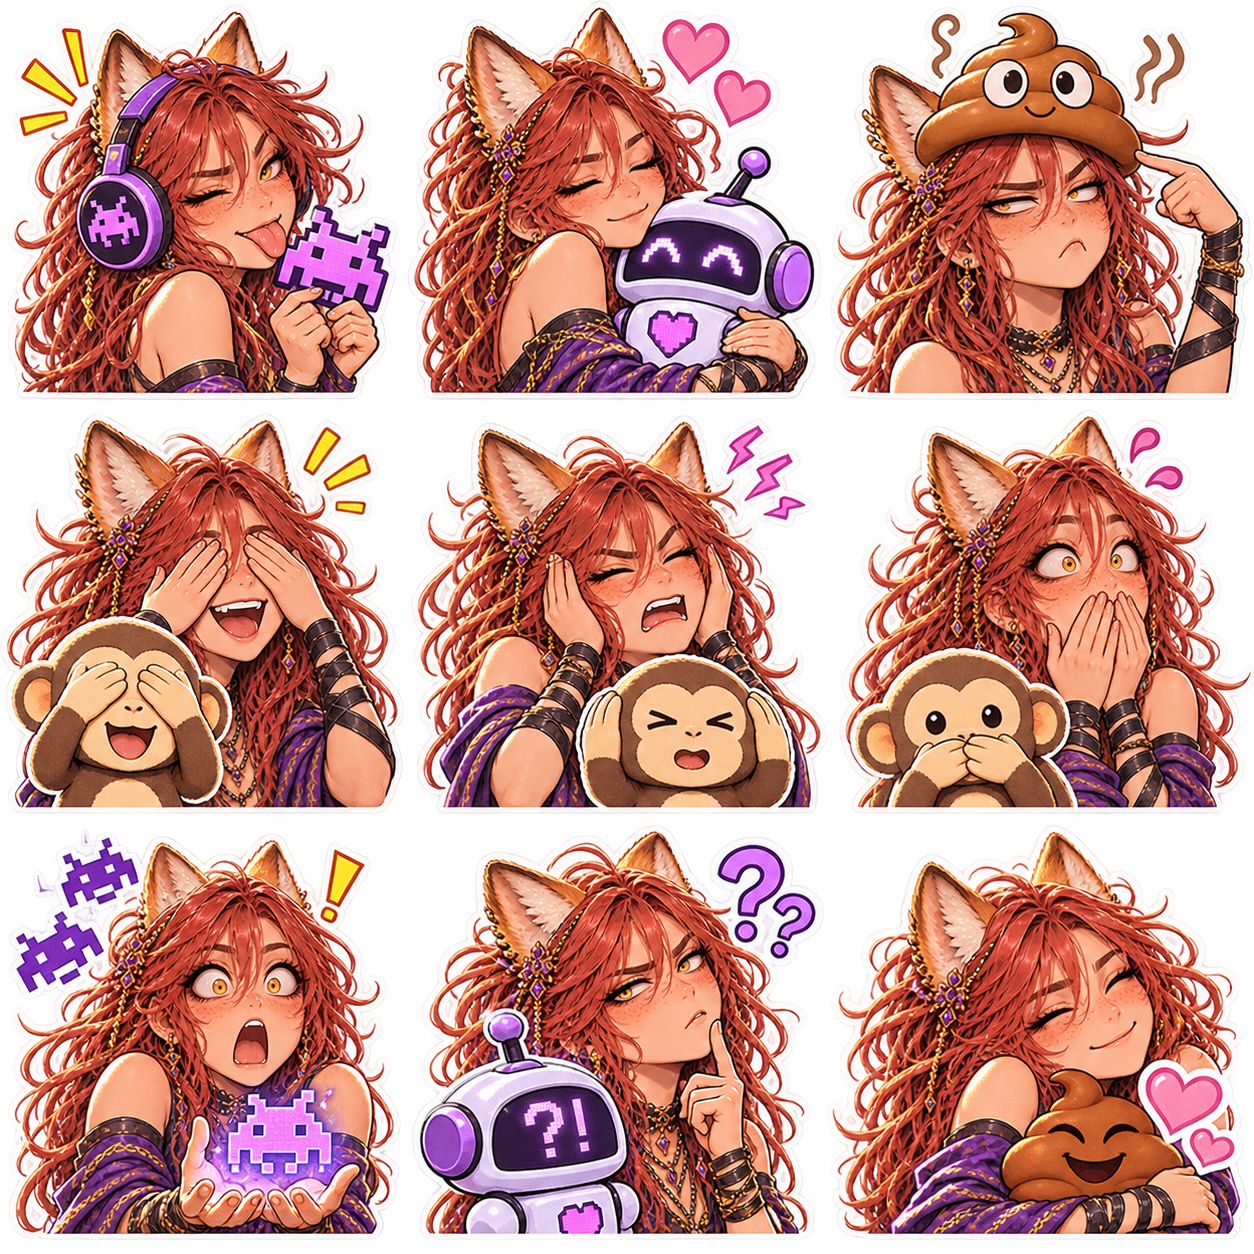

In [ ]:
from IPython.display import Image, display
import os

image_path = '/Anime Fox Elf Gamer Sticker Sheet.png'
if os.path.exists(image_path):
    display(Image(filename=image_path))
else:
    print(f"File '{image_path}' not found. Please upload it using the cell above.")

In [ ]:
import cv2
import numpy as np
from PIL import Image

image_path = "/Anime Fox Elf Gamer Sticker Sheet.png"
img = cv2.imread(image_path)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 1. Threshold to isolate the borders
_, thresh = cv2.threshold(gray, 220, 255, cv2.THRESH_BINARY)

# 2. Apply morphological erosion to separate touching borders
kernel = np.ones((5, 5), np.uint8)
eroded = cv2.erode(thresh, kernel, iterations=1)

# 3. Find contours
contours, _ = cv2.findContours(
    eroded, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

pil_img = Image.open(image_path)
saved_count = 0

# We sort the contours from top-to-bottom, left-to-right to maintain order
bounding_boxes = []
for cnt in contours:
    x, y, w, h = cv2.boundingRect(cnt)
    # Only keep objects of typical sticker size (e.g., larger than 150x150 but smaller than 90% of the image)
    if 150 < w < (img.shape[1] * 0.9) and 150 < h < (img.shape[0] * 0.9):
        bounding_boxes.append((x, y, w, h))

# Sort bounding boxes top-to-bottom, then left-to-right
bounding_boxes = sorted(bounding_boxes, key=lambda b: (b[1] // 300, b[0]))

for x, y, w, h in bounding_boxes:
    padding = 15
    box = (
        max(0, x - padding),
        max(0, y - padding),
        min(pil_img.width, x + w + padding),
        min(pil_img.height, y + h + padding),
    )

    sticker = pil_img.crop(box)
    saved_count += 1
    sticker.save(f"emberstates_extracted_sticker_{saved_count}.png")

print(f"Successfully isolated and saved {saved_count} individual stickers!")

Successfully isolated and saved 1 individual stickers!


### Diagnostic: Visualizing Thresholding Mask and Detected Contours
Let's plot the mask and draw the bounding boxes on the original image to see exactly why only 2 regions were successfully extracted.

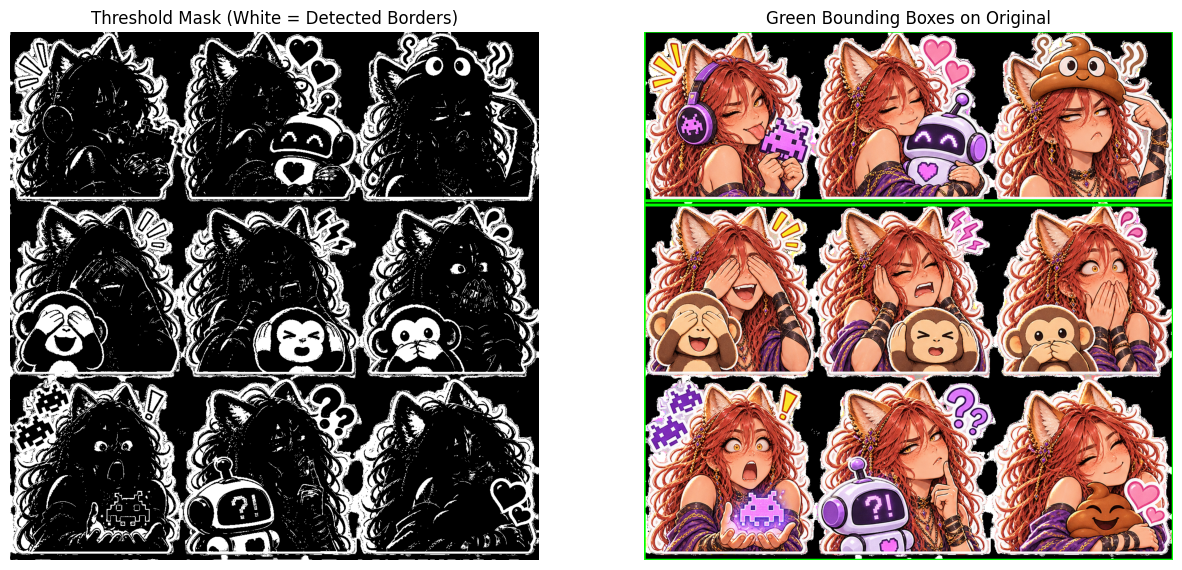

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Reload image and process
img = cv2.imread(image_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
_, thresh = cv2.threshold(gray, 200, 255, cv2.THRESH_BINARY)
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Create a copy to draw boxes on
boxed_img = img_rgb.copy()

for cnt in contours:
    x, y, w, h = cv2.boundingRect(cnt)
    if w > 50 and h > 50:
        cv2.rectangle(boxed_img, (x, y), (x + w, y + h), (0, 255, 0), 5)

# Plot threshold mask and bounding boxes
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
axes[0].imshow(thresh, cmap='gray')
axes[0].set_title('Threshold Mask (White = Detected Borders)')
axes[0].axis('off')

axes[1].imshow(boxed_img)
axes[1].set_title('Green Bounding Boxes on Original')
axes[1].axis('off')

plt.show()

In [ ]:
def ember_emotions_in_review(*emotions):
  """Processes and registers multiple mood/emotion states

  for review in the Emberstates topology engine.
  """
  registered_states = []
  for state in emotions:
    # Map each incoming state ID to your engine pipeline
    state_name = f"ember_state_{state}"
    registered_states.append(state_name)

  return registered_states


# Example usage matching your input:
active_review_batch = ember_emotions_in_review(2, 3, 4, 5, 6, 7)
print(active_review_batch)

['ember_state_2', 'ember_state_3', 'ember_state_4', 'ember_state_5', 'ember_state_6', 'ember_state_7']
